In [2]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import torch
import random
import time

# Add the current directory to the path to ensure the notebook can find the local module
if os.path.abspath('.') not in sys.path:
    sys.path.append(os.path.abspath('.'))

from random_besov import FastWaveletBatchGenerator
from random_besov_ds import FastWaveletBatchGenerator_ds
from matplotlib.lines import Line2D

In [3]:
###### Sampling Utilities
def sample_unit_ball(n, d):
    z = np.random.normal(size=(n, d))
    z /= np.linalg.norm(z, axis=1, keepdims=True)
    r = np.random.uniform(size=(n, 1)) ** (1 / d)
    return r * z


def sample_stiefel(d, p):
    if p > d:
        raise ValueError("p must be <= d")

    Z = np.random.normal(size=(d, p))
    Q, R = np.linalg.qr(Z)

    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1
    Q *= signs
    return Q


def random_project(X, p):
    d = X.shape[1]
    U = sample_stiefel(d, p)
    X_projected = (np.matmul(X, U) + 1) / 2
    return X_projected

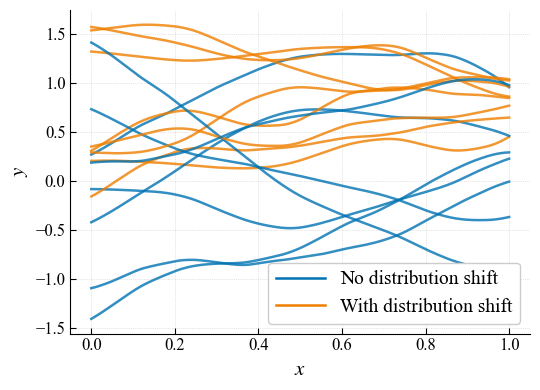

In [19]:
X_list = []
num_functions = 8
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 

params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2.0, 'seed': 42*1}
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()

params = {'d': 1, 'alpha': 4, 'J': 10, 'C0': 2.0, 'seed': 42*2}
random_besov_generator_ds = FastWaveletBatchGenerator_ds(wavelet='db6', cascade_level=8)
Y_list_ds = random_besov_generator_ds.generate_batch(X_list, params)
random_besov_generator_ds.cleanup()


# Plot the results
# plt.style.use('seaborn-v0_8-whitegrid')
# fig, ax = plt.subplots(figsize=(8, 6))

# for i in range(num_functions):
#     x_coords = X_list[i].flatten()
#     y_coords = Y_list[i]
#     ax.plot(x_coords, y_coords, color='C0', alpha=0.9, lw=2.5)
#     y_coords_ds = Y_list_ds[i]
#     ax.plot(x_coords, y_coords_ds, color='C1', alpha=0.9, lw=2.5)

# ax.set_xlabel('$x$', fontsize=20)
# ax.set_ylabel('$y$', fontsize=20)
# legend_handles = [
#     Line2D([0], [0], color='C0', lw=2.5, label='No distribution shift'),
#     Line2D([0], [0], color='C1', lw=2.5, label='With distribution shift'),
# ]
# legend = ax.legend(
#     handles=legend_handles,
#     fontsize=20,
#     frameon=True,
#     fancybox=True,
#     framealpha=1.0
# )

# legend.get_frame().set_edgecolor('grey')
# legend.get_frame().set_linewidth(1.0)
# legend.get_frame().set_facecolor('white')
# plt.tick_params(axis='both', which='major', labelsize=15)
# plt.xlabel('$x$', fontsize=20)
# plt.ylabel('$y$', fontsize=20)

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Times New Roman",
#     "text.latex.preamble": r"\usepackage{lmodern}\usepackage[T1]{fontenc}"
# })

# ax.grid(True)
# plt.savefig("random_besov_ds_alpha=4.pdf", bbox_inches='tight')
# plt.show()


import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mpl.rcParams.update({
    "font.family":         "serif",
    "font.serif":          ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset":    "stix",
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "axes.linewidth":      0.8,
    "xtick.direction":     "in",
    "ytick.direction":     "in",
    "xtick.major.size":    4,
    "ytick.major.size":    4,
    "xtick.major.width":   0.8,
    "ytick.major.width":   0.8,
    "axes.grid":           True,
    "grid.linestyle":      ":",
    "grid.linewidth":      0.5,
    "grid.alpha":          0.6,
    "grid.color":          "#aaaaaa",
    "legend.frameon":      True,
    "legend.edgecolor":    "#cccccc",
    "legend.framealpha":   1.0,
    "legend.handlelength": 2.5,
})

BLUE   = "#0072B2"
ORANGE = "#EF7F00"

fig, ax = plt.subplots(figsize=(5.5, 4.0))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    ax.plot(x_coords, Y_list[i],    color=BLUE,   alpha=0.8, lw=1.8)
    ax.plot(x_coords, Y_list_ds[i], color=ORANGE, alpha=0.8, lw=1.8)

legend_handles = [
    Line2D([0], [0], color=BLUE,   lw=1.8, label="No distribution shift"),
    Line2D([0], [0], color=ORANGE, lw=1.8, label="With distribution shift"),
]
ax.legend(handles=legend_handles, fontsize=14)

ax.set_xlabel(r"$x$", fontsize=15)
ax.set_ylabel(r"$y$", fontsize=15)
ax.tick_params(labelsize=12)

fig.tight_layout()
fig.savefig("random_besov_ds_alpha=4.pdf", dpi=300, bbox_inches="tight")
plt.show()

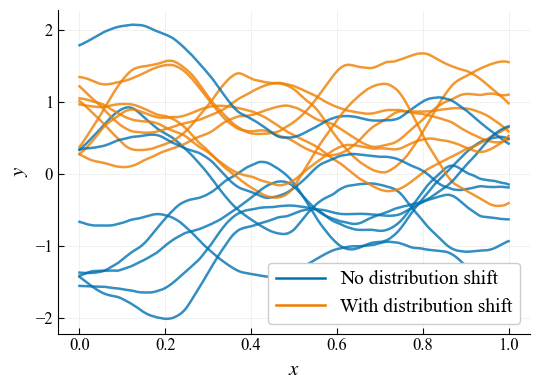

In [20]:
X_list = []
num_functions = 8
for i in range(num_functions):
    X_list.append(np.linspace(0, 1, 4096).reshape(-1, 1)) 

params = {'d': 1, 'alpha': 2, 'J': 10, 'C0': 2.0, 'seed': 42*3}
random_besov_generator = FastWaveletBatchGenerator(wavelet='db6', cascade_level=8)
Y_list = random_besov_generator.generate_batch(X_list, params)
random_besov_generator.cleanup()

params = {'d': 1, 'alpha': 2, 'J': 10, 'C0': 2.0, 'seed': 42*4}
random_besov_generator_ds = FastWaveletBatchGenerator_ds(wavelet='db6', cascade_level=8)
Y_list_ds = random_besov_generator_ds.generate_batch(X_list, params)
random_besov_generator_ds.cleanup()


# Plot 
fig, ax = plt.subplots(figsize=(5.5, 4.0))

for i in range(num_functions):
    x_coords = X_list[i].flatten()
    ax.plot(x_coords, Y_list[i],    color=BLUE,   alpha=0.8, lw=1.8)
    ax.plot(x_coords, Y_list_ds[i], color=ORANGE, alpha=0.8, lw=1.8)

legend_handles = [
    Line2D([0], [0], color=BLUE,   lw=1.8, label="No distribution shift"),
    Line2D([0], [0], color=ORANGE, lw=1.8, label="With distribution shift"),
]
ax.legend(handles=legend_handles, fontsize=14)

ax.set_xlabel(r"$x$", fontsize=15)
ax.set_ylabel(r"$y$", fontsize=15)
ax.tick_params(labelsize=12)

fig.tight_layout()
fig.savefig("random_besov_ds_alpha=2.pdf", dpi=300, bbox_inches="tight")
plt.show()